In [1]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
from scipy.stats import rankdata, norm

In [33]:
WT = ad.read_h5ad("WT_FAPs_cell.h5ad")
mdx = ad.read_h5ad("mdx_FAPs_cell.h5ad")
TG = ad.read_h5ad("TG_FAPs_cell.h5ad")

In [34]:
all_FAPs = ad.concat([WT, mdx, TG])
all_FAPs_raw = all_FAPs.raw.to_adata()
all_FAPs_raw.obsm = all_FAPs.obsm
all_FAPs = all_FAPs_raw

In [43]:
all_FAPs.obs

,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,leiden,condition
AAACCCAAGAGCAGCT-1-0,2599,2599,7387.0,174.0,2.355489,Fibs,WT
AAACGAAAGACATACA-1-0,3660,3660,13488.0,254.0,1.883155,Fibs,WT
AAACGAAAGGGTCAAC-1-0,664,664,1086.0,30.0,2.762431,Fibs,WT
AAACGCTCAACCTATG-1-0,2300,2299,4459.0,77.0,1.726845,Fibs,WT
AAACGCTCAGCGTGCT-1-0,3324,3324,11791.0,254.0,2.154186,Fibs,WT
...,...,...,...,...,...,...,...
TTTGTTGCATCTCATT-1-2,2993,2992,8958.0,113.0,1.261442,Fibs,mdx-TG
TTTGTTGGTACCTGTA-1-2,2080,2080,5583.0,83.0,1.486656,Fibs,mdx-TG
TTTGTTGGTTCGAGCC-1-2,1693,1693,3852.0,57.0,1.479751,Fibs,mdx-TG
TTTGTTGTCATTGGTG-1-2,2175,2175,6679.0,300.0,4.491691,Fibs,mdx-TG


In [ ]:
## save the FAPs from single cell explicitly so I don't get confused weeks later...
all_FAPs.write_h5ad("single_cell_FAPs.h5ad")

In [2]:
all_FAPs = ad.read_h5ad("single_cell_FAPs.h5ad")

In [6]:
genes = [
    # YAP/TAZ/TEAD
    'YAP1', 'WWTR1', 'TEAD1', 'TEAD2', 'TEAD3', 'TEAD4',

    # negative regulators (some below as targets)
    'STK3', 'STK4', 'SAV1', 'MOB1A', 'MOB1B', 'NF2', 'AMOT', 'LATS1', 'AMOTL1', 'WWC1', 'WWC2', 'PTPN14',

    # curated YAP/TAZ hippo/mechano gene list
    ## from PMID: 29317486, PMID: 19324877, PMID: 30380420
    'ANKRD1', 'CCN1', 'CCN2', 'CDC42EP3', 'PARVA', 'NEDD9', 'CSRP1', 'FMN2', 'THBS1', 'DCN', 'SPARC', 'COL6A2', 'MFAP5', 'LTBP1', 'PXDN', 
    'INHBA', 'TGFB2', 'CDH13', 'DAB2', 'MYOF', 'ASAP1', 'CCDC80', 'DOCK5', 'ARHGEF17', 'NUAK2', 'LATS2', 'AMOTL2'
]

In [7]:
def pairwise_auc(adata, group_key, group1, group2, genes, layer=None):
    sub = adata[adata.obs[group_key].isin([group1, group2])]
    labels = sub.obs[group_key].values
    mat = sub[:, genes].layers[layer] if layer else sub[:, genes].X
    mat = mat.toarray() if hasattr(mat, "toarray") else np.asarray(mat)
    n1 = np.sum(labels == group1)
    n2 = np.sum(labels == group2)
    aucs = {}
    for i, gene in enumerate(genes):
        ranks = rankdata(mat[:, i])
        rank_sum1 = ranks[labels == group1].sum()
        u1 = rank_sum1 - n1 * (n1 + 1) / 2
        aucs[gene] = u1 / (n1 * n2)
    return pd.Series(aucs)

In [8]:
df = pd.DataFrame({
    "WT_vs_mdx": pairwise_auc(all_FAPs, "condition", "mdx", "WT", genes),
    "WT_vs_TG": pairwise_auc(all_FAPs, "condition", "mdx-TG", "WT", genes),
    "mdx_vs_TG": pairwise_auc(all_FAPs, "condition", "mdx-TG", "mdx", genes),
}) - 0.5

In [9]:
print(df)

          WT_vs_mdx  WT_vs_TG  mdx_vs_TG
YAP1       0.042772  0.015629  -0.027179
WWTR1     -0.000608 -0.019934  -0.020756
TEAD1      0.137964  0.053400  -0.086500
TEAD2      0.007396  0.006401  -0.000972
TEAD3      0.022201  0.008848  -0.013394
TEAD4     -0.001887 -0.001189   0.000696
STK3       0.034012  0.047725   0.015930
STK4      -0.029880 -0.028374   0.000481
SAV1       0.011829  0.006624  -0.005538
MOB1A     -0.004172 -0.006732  -0.003832
MOB1B      0.024227  0.019429  -0.004134
NF2       -0.002472 -0.011940  -0.010379
AMOT       0.014957  0.013632  -0.001099
LATS1      0.017791  0.007946  -0.009944
AMOTL1    -0.042962 -0.008089   0.033939
WWC1       0.002332  0.000056  -0.002276
WWC2      -0.030556 -0.040285  -0.012302
PTPN14     0.050538  0.028890  -0.021321
ANKRD1     0.001196  0.000917  -0.000278
CCN1      -0.006017 -0.018124  -0.012695
CCN2       0.056019  0.045599  -0.008782
CDC42EP3  -0.010262 -0.018553  -0.008538
PARVA      0.053483  0.003913  -0.050189
NEDD9     -0.028

In [12]:
df.to_excel('scored_YAP_pathway.xlsx', index=True)

In [13]:
sc.tl.score_genes(all_FAPs, gene_list=genes)

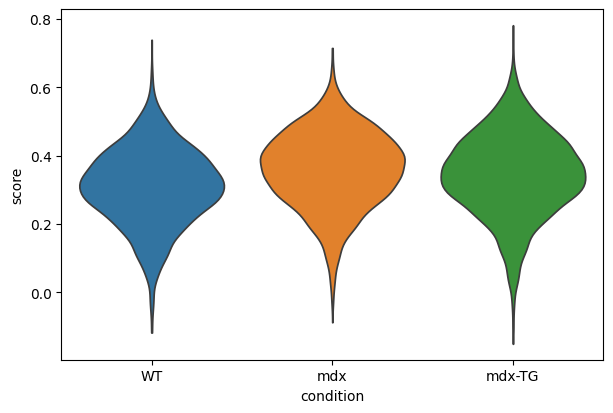

In [14]:
sc.pl.violin(all_FAPs, 'score', groupby='condition', size=0)